# Signal zoo: how many of the usual signals survive?

Pre-registered in `preregistration.md`. Results come from `studies/zoo.py`; this notebook reads its outputs.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
REPORTS = Path('..') / 'reports'
res = json.loads((REPORTS / 'zoo.json').read_text())

## Funnel

In [2]:
pd.DataFrame({k: v['counts'] for k, v in res.items()})

,zoo_primary,zoo_sensitivity
tested,128,128
positive gross,69,69
positive net of costs,1,17
significant after Holm,0,0
survives deflation,0,0


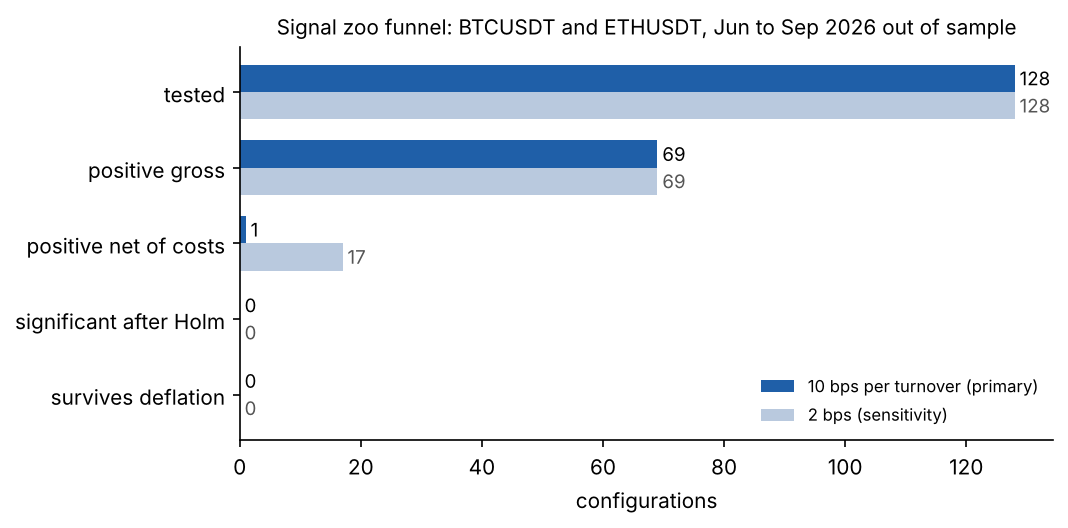

In [3]:
display(Image(REPORTS / 'zoo_funnel.png', width=700))

## Best configurations at the primary cost (10 bps per unit turnover)
Sharpe ratios annualised: 8,760 periods a year for 60-minute bars and 35,040 for 15-minute bars (crypto trades 24/7).

In [4]:
t = pd.read_csv(REPORTS / 'zoo_primary_trials.csv')
ppy = np.where(t['params'].str.contains('60min'), 8760, 35040)
t['gross_sr_ann'], t['net_sr_ann'] = t['gross_sr'] * np.sqrt(ppy), t['net_sr'] * np.sqrt(ppy)
t.sort_values('net_sr', ascending=False).head(8)[['signal', 'params', 'gross_sr_ann', 'net_sr_ann', 'p_net', 'p_adj', 'dsr', 'turnover']].round(3)

,signal,params,gross_sr_ann,net_sr_ann,p_net,p_adj,dsr,turnover
113,vol_breakout,"{""lookback"": 48, ""k"": 3, ""data"": ""ETHUSDT_60min""}",2.954,0.466,0.390,1.0,0.0,0.050
115,vol_breakout,"{""lookback"": 96, ""k"": 3, ""data"": ""ETHUSDT_60min""}",2.065,-0.243,0.555,1.0,0.0,0.047
99,tsmom,"{""lookback"": 96, ""data"": ""ETHUSDT_60min""}",0.617,-0.855,0.688,1.0,0.0,0.091
34,tsmom,"{""lookback"": 48, ""data"": ""BTCUSDT_60min""}",1.560,-0.877,0.693,1.0,0.0,0.114
105,zscore_mr,"{""lookback"": 96, ""entry"": 2, ""data"": ""ETHUSDT_...",0.682,-1.114,0.745,1.0,0.0,0.058
109,bollinger,"{""lookback"": 48, ""k"": 2, ""data"": ""ETHUSDT_60min""}",0.466,-1.796,0.838,1.0,0.0,0.076
98,tsmom,"{""lookback"": 48, ""data"": ""ETHUSDT_60min""}",0.368,-1.896,0.861,1.0,0.0,0.140
59,flow_imbalance,"{""lookback"": 4, ""threshold"": -0.2, ""data"": ""BT...",3.124,-1.909,0.847,1.0,0.0,0.057


## By signal family: gross edge versus what costs take

In [5]:
t.groupby('signal')[['gross_sr_ann', 'net_sr_ann', 'turnover']].median().round(2).sort_values('net_sr_ann', ascending=False)

,gross_sr_ann,net_sr_ann,turnover
signal,,,
rsi,-0.72,-5.12,0.07
vol_breakout,0.34,-6.53,0.08
tsmom,0.01,-6.66,0.20
zscore_mr,-0.08,-7.19,0.12
bollinger,0.20,-7.72,0.12
time_of_day,1.26,-11.61,0.15
flow_imbalance,0.00,-21.51,0.31
xgb_direction,0.57,-28.22,0.56


## Probability of backtest overfitting by dataset

In [6]:
pd.DataFrame({k: v['pbo'] for k, v in res.items()}).round(3)

,zoo_primary,zoo_sensitivity
BTCUSDT_15min,0.000,0.180
BTCUSDT_60min,0.161,0.461
ETHUSDT_15min,0.000,0.449
ETHUSDT_60min,0.240,0.590
